In [3]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Project paths
PROJECT_DIR = Path(
    r"C:\Users\pulit\OneDrive\Desktop\University\Y4S1\research\xai-cornea-grading"
)

IMAGE_DATA_DIR = PROJECT_DIR / "ml/grading/image/data/processed"
IMAGE_DIR = IMAGE_DATA_DIR / "images"
MANIFEST_PATH = IMAGE_DATA_DIR / "clean_image_manifest.csv"

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Manifest exists:", MANIFEST_PATH.exists())
print("Image directory exists:", IMAGE_DIR.exists())

PyTorch: 2.14.1+cu126
CUDA available: True
Manifest exists: True
Image directory exists: True


In [4]:
# Load the clean image manifest
manifest = pd.read_csv(MANIFEST_PATH)

# Keep only specialist-labelled records for supervised classification
labelled_manifest = manifest[
    manifest["Tissue_Grade_Clean"].isin(["A+", "A", "B"])
].copy()

# Check that every referenced image exists
labelled_manifest["Image_Exists"] = labelled_manifest[
    "Selected_Image"
].apply(lambda p: (IMAGE_DIR / str(p)).is_file())

print("Manifest records:", len(manifest))
print("Labelled records:", len(labelled_manifest))
print("Unlabelled records:", len(manifest) - len(labelled_manifest))
print("Missing image files:", (~labelled_manifest["Image_Exists"]).sum())

print("\nGrade distribution:")
print(labelled_manifest["Tissue_Grade_Clean"].value_counts())

if (~labelled_manifest["Image_Exists"]).any():
    display(
        labelled_manifest.loc[
            ~labelled_manifest["Image_Exists"],
            ["Tissue_ID", "Selected_Image"]
        ]
    )

Manifest records: 1024
Labelled records: 1009
Unlabelled records: 15
Missing image files: 0

Grade distribution:
Tissue_Grade_Clean
A+    530
A     314
B     165
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

# Exclude any unresolved tissue IDs if they are present in the clean manifest
review_ids = {
    "NEB-2024-08-16259 R",
    "NEB-2025-09-17471 R",
}

labelled_manifest = labelled_manifest[
    ~labelled_manifest["Tissue_ID"].isin(review_ids)
].copy()

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    labelled_manifest,
    test_size=0.30,
    random_state=SEED,
    stratify=labelled_manifest["Tissue_Grade_Clean"],
)

# Second split: divide temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["Tissue_Grade_Clean"],
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nGrade distribution by split:")
for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}:")
    print(split["Tissue_Grade_Clean"].value_counts().sort_index())

Training: 706
Validation: 151
Test: 152

Grade distribution by split:

Train:
Tissue_Grade_Clean
A     220
A+    371
B     115
Name: count, dtype: int64

Validation:
Tissue_Grade_Clean
A     47
A+    79
B     25
Name: count, dtype: int64

Test:
Tissue_Grade_Clean
A     47
A+    80
B     25
Name: count, dtype: int64


In [6]:
# Verify that no tissue appears in more than one split
train_ids = set(train_df["Tissue_ID"])
val_ids = set(val_df["Tissue_ID"])
test_ids = set(test_df["Tissue_ID"])

print("Train/validation overlap:", len(train_ids & val_ids))
print("Train/test overlap:", len(train_ids & test_ids))
print("Validation/test overlap:", len(val_ids & test_ids))

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\nAll split integrity checks passed.")

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0

All split integrity checks passed.


In [7]:
# Save split assignments without copying the image files
SPLIT_DIR = IMAGE_DATA_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.assign(Split="train").to_csv(
    SPLIT_DIR / "train.csv", index=False
)
val_df.assign(Split="validation").to_csv(
    SPLIT_DIR / "validation.csv", index=False
)
test_df.assign(Split="test").to_csv(
    SPLIT_DIR / "test.csv", index=False
)

# Also save one combined file for convenient reuse
split_manifest = pd.concat(
    [
        train_df.assign(Split="train"),
        val_df.assign(Split="validation"),
        test_df.assign(Split="test"),
    ],
    ignore_index=True,
)

split_manifest.to_csv(
    SPLIT_DIR / "image_split_manifest.csv", index=False
)

print("Saved split files to:", SPLIT_DIR)
print("Total assignments:", len(split_manifest))
print(split_manifest["Split"].value_counts())

Saved split files to: C:\Users\pulit\OneDrive\Desktop\University\Y4S1\research\xai-cornea-grading\ml\grading\image\data\processed\splits
Total assignments: 1009
Split
train         706
test          152
validation    151
Name: count, dtype: int64


In [8]:
from PIL import Image
from collections import Counter

# Inspect a sample of training images
sample_paths = [
    IMAGE_DIR / str(filename)
    for filename in train_df["Selected_Image"].head(50)
]

dimensions = Counter()
modes = Counter()
formats = Counter()
unreadable = []

for path in sample_paths:
    try:
        with Image.open(path) as img:
            dimensions[img.size] += 1
            modes[img.mode] += 1
            formats[img.format] += 1
    except Exception as exc:
        unreadable.append((str(path), str(exc)))

print("Sample size:", len(sample_paths))
print("\nImage dimensions (width, height):")
print(dimensions.most_common(10))

print("\nColor modes:")
print(modes)

print("\nFormats:")
print(formats)

print("\nUnreadable images:", len(unreadable))
if unreadable:
    print(unreadable[:5])

Sample size: 50

Image dimensions (width, height):
[((1296, 972), 50)]

Color modes:
Counter({'L': 50})

Formats:
Counter({'JPEG': 50})

Unreadable images: 0


In [9]:
import numpy as np
from PIL import Image

pixel_mins = []
pixel_maxs = []
pixel_means = []
pixel_stds = []

for path in sample_paths:
    with Image.open(path) as img:
        pixels = np.asarray(img, dtype=np.float32)

    pixel_mins.append(pixels.min())
    pixel_maxs.append(pixels.max())
    pixel_means.append(pixels.mean())
    pixel_stds.append(pixels.std())

print("Pixel intensity range: 0–255")
print(f"Minimum intensity across images: {min(pixel_mins):.0f}")
print(f"Maximum intensity across images: {max(pixel_maxs):.0f}")
print(f"Mean image intensity: {np.mean(pixel_means):.2f}")
print(f"Mean image standard deviation: {np.mean(pixel_stds):.2f}")
print(f"Images with zero intensity variation: {sum(s == 0 for s in pixel_stds)}")

Pixel intensity range: 0–255
Minimum intensity across images: 0
Maximum intensity across images: 255
Mean image intensity: 80.00
Mean image standard deviation: 43.99
Images with zero intensity variation: 0


In [10]:
from PIL import Image
import numpy as np

IMAGE_SIZE = (224, 224)

def preprocess_image(image_path):
    """Load a grayscale image, resize it, and scale intensities to [0, 1]."""
    with Image.open(image_path) as img:
        img = img.convert("L")
        img = img.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        array = np.asarray(img, dtype=np.float32) / 255.0

    # Shape: (height, width, 1)
    return array[..., np.newaxis]


# Test preprocessing on one training image
example_path = IMAGE_DIR / str(train_df.iloc[0]["Selected_Image"])
processed = preprocess_image(example_path)

print("Processed shape:", processed.shape)
print("Data type:", processed.dtype)
print("Minimum pixel value:", processed.min())
print("Maximum pixel value:", processed.max())

assert processed.shape == (224, 224, 1)
assert processed.min() >= 0.0 and processed.max() <= 1.0
print("\nPreprocessing check passed.")

Processed shape: (224, 224, 1)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 0.68235296

Preprocessing check passed.


In [11]:
from PIL import Image
import numpy as np

IMAGE_SIZE = 224

def preprocess_image(image_path):
    """Resize a grayscale image proportionally and pad it to a square."""
    with Image.open(image_path) as img:
        img = img.convert("L")

        # Preserve the original aspect ratio
        img.thumbnail(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.LANCZOS
        )

        # Center the image on a black square canvas
        canvas = Image.new("L", (IMAGE_SIZE, IMAGE_SIZE), color=0)

        left = (IMAGE_SIZE - img.width) // 2
        top = (IMAGE_SIZE - img.height) // 2
        canvas.paste(img, (left, top))

        array = np.asarray(canvas, dtype=np.float32) / 255.0

    return array[..., np.newaxis]


# Test the revised preprocessing
processed = preprocess_image(example_path)

print("Processed shape:", processed.shape)
print("Data type:", processed.dtype)
print("Pixel range:", (processed.min(), processed.max()))

assert processed.shape == (224, 224, 1)
assert processed.dtype == np.float32
assert 0 <= processed.min() <= processed.max() <= 1

print("Aspect-ratio-preserving preprocessing passed.")

Processed shape: (224, 224, 1)
Data type: float32
Pixel range: (np.float32(0.0), np.float32(0.6862745))
Aspect-ratio-preserving preprocessing passed.


In [12]:
import sklearn
import torch
import torchvision

print("scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

scikit-learn: 1.9.1
PyTorch: 2.14.1+cu126
TorchVision: 0.29.1+cu126
Selected device: cuda


In [13]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Total VRAM (GB):",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)
    )

PyTorch: 2.14.1+cu126
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total VRAM (GB): 6.0


In [14]:
from tqdm.auto import tqdm

def load_image_arrays(split_df):
    images = []
    labels = []

    for _, row in tqdm(split_df.iterrows(), total=len(split_df)):
        image_path = IMAGE_DIR / str(row["Selected_Image"])
        images.append(preprocess_image(image_path))
        labels.append(row["Tissue_Grade_Clean"])

    X = np.stack(images).astype(np.float32)
    y = np.array(labels)

    return X, y


# Load training and validation data only
X_train, y_train = load_image_arrays(train_df)
X_val, y_val = load_image_arrays(val_df)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Training labels:", pd.Series(y_train).value_counts().to_dict())
print("Validation labels:", pd.Series(y_val).value_counts().to_dict())

  0%|          | 0/706 [00:00<?, ?it/s]

  0%|          | 0/151 [00:00<?, ?it/s]

Training images: (706, 224, 224, 1)
Validation images: (151, 224, 224, 1)
Training labels: {'A+': 371, 'A': 220, 'B': 115}
Validation labels: {'A+': 79, 'A': 47, 'B': 25}


In [15]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Consistent class mapping
CLASS_NAMES = ["A", "A+", "B"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

def to_tensors(X, y):
    # NHWC -> NCHW
    X_tensor = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()

    # Convert string labels to integer class indices
    y_encoded = np.array([CLASS_TO_IDX[label] for label in y])
    y_tensor = torch.tensor(y_encoded, dtype=torch.long)

    return X_tensor, y_tensor


X_train_tensor, y_train_tensor = to_tensors(X_train, y_train)
X_val_tensor, y_val_tensor = to_tensors(X_val, y_val)

print("Class mapping:", CLASS_TO_IDX)
print("Training tensor:", X_train_tensor.shape, X_train_tensor.dtype)
print("Training labels:", y_train_tensor.shape, y_train_tensor.dtype)
print("Validation tensor:", X_val_tensor.shape)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Class mapping: {'A': 0, 'A+': 1, 'B': 2}
Training tensor: torch.Size([706, 1, 224, 224]) torch.float32
Training labels: torch.Size([706]) torch.int64
Validation tensor: torch.Size([151, 1, 224, 224])
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [16]:
import torch.nn as nn

class CorneaCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            # 224 x 224 -> 112 x 112
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 112 x 112 -> 56 x 56
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 56 x 56 -> 28 x 28
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Reduce spatial dimensions
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = CorneaCNN().to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(model)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Model device:", next(model.parameters()).device)

CorneaCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(star

In [17]:
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 16

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

# Check one batch
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Batch image dtype:", images.dtype)
print("Batch labels:", labels[:10].tolist())

Batch image shape: torch.Size([16, 1, 224, 224])
Batch label shape: torch.Size([16])
Batch image dtype: torch.float32
Batch labels: [1, 0, 0, 2, 1, 1, 0, 1, 1, 1]


In [18]:
import copy
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

# Training settings
MAX_EPOCHS = 30
PATIENCE = 5

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 30
Early stopping patience: 5


In [19]:
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

history = []

for epoch in range(MAX_EPOCHS):
    # Training phase
    model.train()
    train_loss_sum = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_loader.dataset)
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    # Validation phase
    model.eval()
    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_f1 = f1_score(
        val_true, val_pred, average="macro", zero_division=0
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )

    # Save the best model based on validation macro F1
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break

# Restore the best validation model
if best_model_state is None:
    raise RuntimeError("Training did not produce a valid model state.")

model.load_state_dict(best_model_state)

history_df = pd.DataFrame(history)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation macro F1: {best_val_f1:.4f}")

Epoch 01/30 | Train loss: 1.0652 | Train macro F1: 0.2938 | Val loss: 1.0255 | Val macro F1: 0.2439
Epoch 02/30 | Train loss: 1.0125 | Train macro F1: 0.2580 | Val loss: 1.0279 | Val macro F1: 0.2887
Epoch 03/30 | Train loss: 0.9911 | Train macro F1: 0.2653 | Val loss: 0.9778 | Val macro F1: 0.2290
Epoch 04/30 | Train loss: 0.9881 | Train macro F1: 0.2807 | Val loss: 1.0322 | Val macro F1: 0.3180
Epoch 05/30 | Train loss: 0.9940 | Train macro F1: 0.2495 | Val loss: 1.0704 | Val macro F1: 0.2290
Epoch 06/30 | Train loss: 0.9840 | Train macro F1: 0.2802 | Val loss: 1.1255 | Val macro F1: 0.2290
Epoch 07/30 | Train loss: 0.9699 | Train macro F1: 0.2621 | Val loss: 1.0658 | Val macro F1: 0.3771
Epoch 08/30 | Train loss: 0.9668 | Train macro F1: 0.2678 | Val loss: 1.1532 | Val macro F1: 0.2290
Epoch 09/30 | Train loss: 0.9641 | Train macro F1: 0.3101 | Val loss: 0.9552 | Val macro F1: 0.2290
Epoch 10/30 | Train loss: 0.9596 | Train macro F1: 0.2744 | Val loss: 1.1036 | Val macro F1: 0.3029


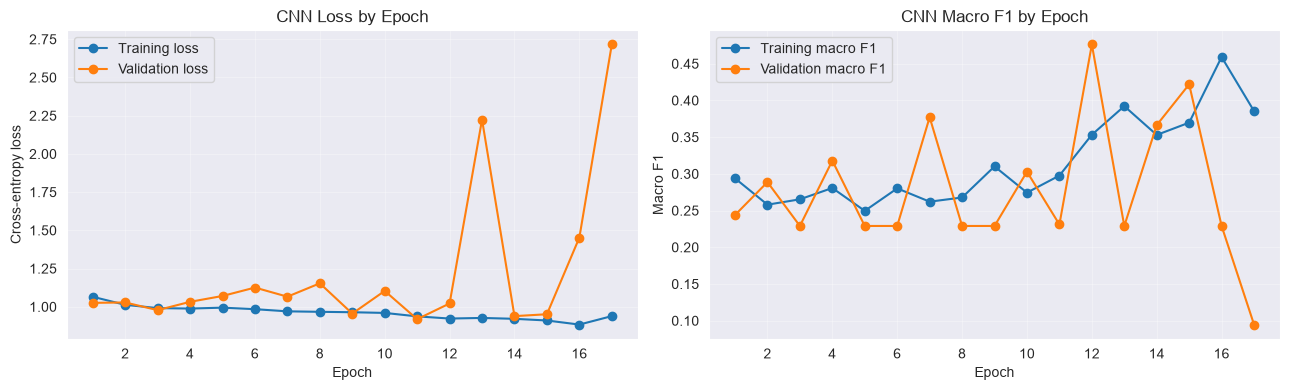

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training loss"
)
axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss"
)
axes[0].set_title("CNN Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    marker="o",
    label="Training macro F1"
)
axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Validation macro F1"
)
axes[1].set_title("CNN Macro F1 by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import torch

model.eval()
val_true = []
val_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        logits = model(images)
        predictions = logits.argmax(dim=1)

        val_true.extend(labels.numpy())
        val_pred.extend(predictions.cpu().numpy())

print("Classification Report:\n")
print(
    classification_report(
        val_true,
        val_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4
    )
)

cm = confusion_matrix(val_true, val_pred, labels=[0, 1, 2])

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in CLASS_NAMES],
    columns=[f"Predicted {c}" for c in CLASS_NAMES]
)

print("\nConfusion Matrix:\n")
print(display(cm_df))

print("\nActual validation class counts:")
print(pd.Series(val_true).map(IDX_TO_CLASS).value_counts())

print("\nPredicted validation class counts:")
print(pd.Series(val_pred).map(IDX_TO_CLASS).value_counts())

Classification Report:

              precision    recall  f1-score   support

           A     0.4074    0.2340    0.2973        47
          A+     0.7818    0.5443    0.6418        79
           B     0.3333    0.9200    0.4894        25

    accuracy                         0.5099       151
   macro avg     0.5075    0.5661    0.4762       151
weighted avg     0.5910    0.5099    0.5093       151


Confusion Matrix:



,Predicted A,Predicted A+,Predicted B
Actual A,11,11,25
Actual A+,15,43,21
Actual B,1,1,23


None

Actual validation class counts:
A+    79
A     47
B     25
Name: count, dtype: int64

Predicted validation class counts:
B     69
A+    55
A     27
Name: count, dtype: int64


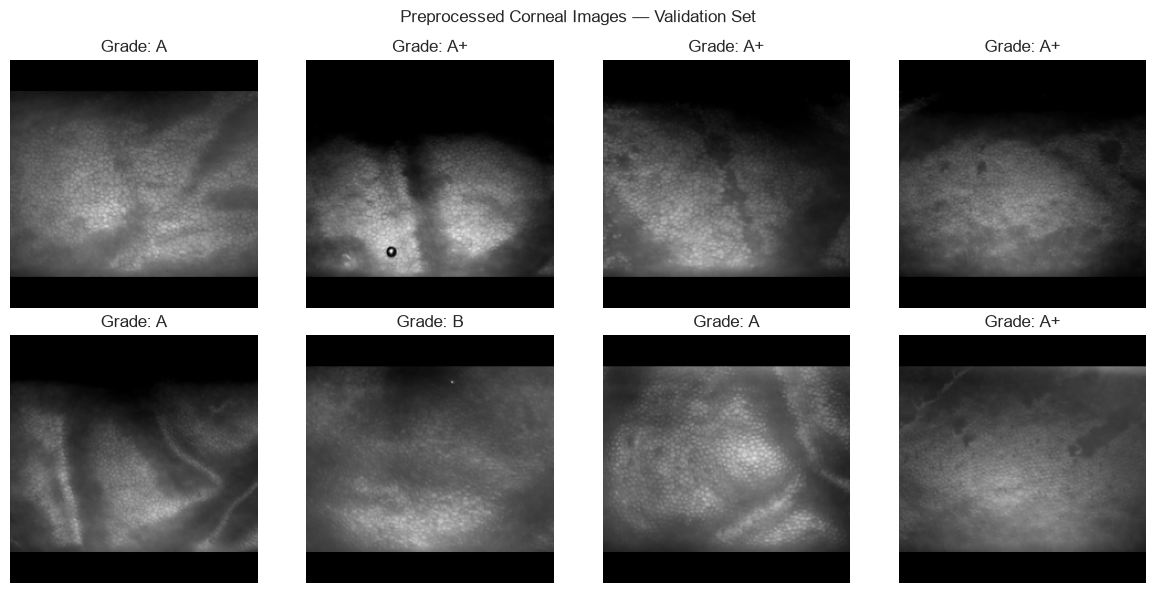

In [24]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, val_df.sample(8, random_state=42).iterrows()):
    image_path = IMAGE_DIR / str(row["Selected_Image"])
    image = preprocess_image(image_path)

    ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Grade: {row['Tissue_Grade_Clean']}")
    ax.axis("off")

plt.suptitle("Preprocessed Corneal Images — Validation Set")
plt.tight_layout()
plt.show()

In [25]:
import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

# Check that the model architecture is available.
model_check = resnet18(weights=None)
print("ResNet-18 architecture: available")
print("Original output classes:", model_check.fc.out_features)

# Check whether pretrained weights are already cached locally.
weights_path = (
    torch.hub.get_dir()
    + "/checkpoints/"
    + ResNet18_Weights.DEFAULT.url.split("/")[-1]
)

from pathlib import Path
print("Pretrained weights cached:", Path(weights_path).exists())

PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
CUDA available: True
ResNet-18 architecture: available
Original output classes: 1000
Pretrained weights cached: False


In [26]:
from torchvision.models import resnet18, ResNet18_Weights

# Download ImageNet-pretrained weights
weights = ResNet18_Weights.DEFAULT

resnet_model = resnet18(weights=weights)

print("Pretrained ResNet-18 loaded successfully.")
print("Device:", device)
print("Pretrained weights:", weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\pulit/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:14<00:00, 3.26MB/s]


Pretrained ResNet-18 loaded successfully.
Device: cuda
Pretrained weights: ResNet18_Weights.IMAGENET1K_V1


In [27]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load the pretrained model
resnet_model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze pretrained feature-extraction layers
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace the original 1000-class layer with 3 corneal grades
num_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(num_features, len(CLASS_NAMES))

# Train on the GPU
resnet_model = resnet_model.to(device)

# Confirm configuration
print("Device:", next(resnet_model.parameters()).device)
print("Output classes:", resnet_model.fc.out_features)
print("Trainable parameters:",
      sum(p.numel() for p in resnet_model.parameters() if p.requires_grad))
print("Total parameters:",
      sum(p.numel() for p in resnet_model.parameters()))

Device: cuda:0
Output classes: 3
Trainable parameters: 1539
Total parameters: 11178051


In [28]:
from torchvision import transforms

# ImageNet normalization values
imagenet_mean = torch.tensor(
    [0.485, 0.456, 0.406], dtype=torch.float32
).view(1, 3, 1, 1)

imagenet_std = torch.tensor(
    [0.229, 0.224, 0.225], dtype=torch.float32
).view(1, 3, 1, 1)


def prepare_resnet_tensors(X_tensor):
    # [N, 1, H, W] -> [N, 3, H, W]
    X_rgb = X_tensor.repeat(1, 3, 1, 1)

    # Normalize each channel using ImageNet statistics
    mean = imagenet_mean.to(X_rgb.device)
    std = imagenet_std.to(X_rgb.device)

    return (X_rgb - mean) / std


X_train_resnet = prepare_resnet_tensors(X_train_tensor)
X_val_resnet = prepare_resnet_tensors(X_val_tensor)

print("Training tensor:", X_train_resnet.shape)
print("Validation tensor:", X_val_resnet.shape)
print("Training dtype:", X_train_resnet.dtype)
print("All training values finite:", torch.isfinite(X_train_resnet).all().item())

Training tensor: torch.Size([706, 3, 224, 224])
Validation tensor: torch.Size([151, 3, 224, 224])
Training dtype: torch.float32
All training values finite: True


In [29]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE_RESNET = 16

train_dataset_resnet = TensorDataset(
    X_train_resnet, y_train_tensor
)

val_dataset_resnet = TensorDataset(
    X_val_resnet, y_val_tensor
)

train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=BATCH_SIZE_RESNET,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader_resnet = DataLoader(
    val_dataset_resnet,
    batch_size=BATCH_SIZE_RESNET,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

images, labels = next(iter(train_loader_resnet))

print("Training batches:", len(train_loader_resnet))
print("Validation batches:", len(val_loader_resnet))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Trainable parameters:",
      sum(p.numel() for p in resnet_model.parameters() if p.requires_grad))

Training batches: 45
Validation batches: 10
Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Trainable parameters: 1539


In [30]:
import copy
import torch.optim as optim
from sklearn.metrics import f1_score

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = optim.Adam(
    resnet_model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MAX_EPOCHS_RESNET = 20
PATIENCE_RESNET = 5

best_val_f1_resnet = -1.0
best_epoch_resnet = 0
epochs_without_improvement_resnet = 0
best_resnet_state = None

print("Loss function:", criterion_resnet)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Maximum epochs:", MAX_EPOCHS_RESNET)
print("Early stopping patience:", PATIENCE_RESNET)
print("Trainable parameters:",
      sum(p.numel() for p in resnet_model.parameters()
          if p.requires_grad))

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 20
Early stopping patience: 5
Trainable parameters: 1539


In [31]:
history_resnet = []

for epoch in range(MAX_EPOCHS_RESNET):
    resnet_model.train()
    train_loss_sum = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad(set_to_none=True)

        logits = resnet_model(images)
        loss = criterion_resnet(logits, labels)

        loss.backward()
        optimizer_resnet.step()

        train_loss_sum += loss.item() * images.size(0)
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_loader_resnet.dataset)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro", zero_division=0
    )

    resnet_model.eval()
    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader_resnet:
            images = images.to(device)
            labels = labels.to(device)

            logits = resnet_model(images)
            loss = criterion_resnet(logits, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = val_loss_sum / len(val_loader_resnet.dataset)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro", zero_division=0
    )

    history_resnet.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS_RESNET} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1_resnet:
        best_val_f1_resnet = val_f1
        best_epoch_resnet = epoch + 1
        best_resnet_state = copy.deepcopy(resnet_model.state_dict())
        epochs_without_improvement_resnet = 0
    else:
        epochs_without_improvement_resnet += 1

    if epochs_without_improvement_resnet >= PATIENCE_RESNET:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break

if best_resnet_state is None:
    raise RuntimeError("ResNet training did not produce a valid model state.")

resnet_model.load_state_dict(best_resnet_state)

history_resnet_df = pd.DataFrame(history_resnet)

print(f"\nBest epoch: {best_epoch_resnet}")
print(f"Best validation macro F1: {best_val_f1_resnet:.4f}")

Epoch 01/20 | Train loss: 1.1085 | Train macro F1: 0.2989 | Val loss: 1.1402 | Val macro F1: 0.2439
Epoch 02/20 | Train loss: 1.0038 | Train macro F1: 0.3189 | Val loss: 1.0093 | Val macro F1: 0.2901
Epoch 03/20 | Train loss: 0.9558 | Train macro F1: 0.3261 | Val loss: 1.0201 | Val macro F1: 0.3488
Epoch 04/20 | Train loss: 0.9278 | Train macro F1: 0.4044 | Val loss: 1.0211 | Val macro F1: 0.2513
Epoch 05/20 | Train loss: 0.9228 | Train macro F1: 0.4105 | Val loss: 1.0108 | Val macro F1: 0.3440
Epoch 06/20 | Train loss: 0.8997 | Train macro F1: 0.4363 | Val loss: 1.0321 | Val macro F1: 0.3600
Epoch 07/20 | Train loss: 0.8853 | Train macro F1: 0.4637 | Val loss: 1.0226 | Val macro F1: 0.3729
Epoch 08/20 | Train loss: 0.8584 | Train macro F1: 0.4893 | Val loss: 1.0326 | Val macro F1: 0.3650
Epoch 09/20 | Train loss: 0.8754 | Train macro F1: 0.4822 | Val loss: 0.9919 | Val macro F1: 0.3259
Epoch 10/20 | Train loss: 0.8455 | Train macro F1: 0.4975 | Val loss: 1.0182 | Val macro F1: 0.3214


In [32]:
# Unfreeze the final residual block
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

# Keep earlier pretrained layers frozen
for param in resnet_model.parameters():
    param.requires_grad = False

# Re-enable layer4 and the classification head
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

for param in resnet_model.fc.parameters():
    param.requires_grad = True

# Use discriminative learning rates
optimizer_finetune = optim.Adam(
    [
        {"params": resnet_model.layer4.parameters(), "lr": 1e-5},
        {"params": resnet_model.fc.parameters(), "lr": 1e-4},
    ],
    weight_decay=1e-4
)

print(
    "Trainable parameters:",
    sum(p.numel() for p in resnet_model.parameters()
        if p.requires_grad)
)
print("Layer4 learning rate: 1e-5")
print("Classification head learning rate: 1e-4")

Trainable parameters: 8395267
Layer4 learning rate: 1e-5
Classification head learning rate: 1e-4


In [33]:
history_finetune = []

MAX_EPOCHS_FINETUNE = 15
PATIENCE_FINETUNE = 5

best_val_f1_finetune = -1.0
best_epoch_finetune = 0
epochs_without_improvement_finetune = 0
best_finetune_state = None

for epoch in range(MAX_EPOCHS_FINETUNE):
    resnet_model.train()
    train_loss_sum = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader_resnet:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_finetune.zero_grad(set_to_none=True)

        logits = resnet_model(images)
        loss = criterion_resnet(logits, labels)

        loss.backward()
        optimizer_finetune.step()

        train_loss_sum += loss.item() * images.size(0)
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_loader_resnet.dataset)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro", zero_division=0
    )

    resnet_model.eval()
    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader_resnet:
            images = images.to(device)
            labels = labels.to(device)

            logits = resnet_model(images)
            loss = criterion_resnet(logits, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = val_loss_sum / len(val_loader_resnet.dataset)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro", zero_division=0
    )

    history_finetune.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS_FINETUNE} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1_finetune:
        best_val_f1_finetune = val_f1
        best_epoch_finetune = epoch + 1
        best_finetune_state = copy.deepcopy(resnet_model.state_dict())
        epochs_without_improvement_finetune = 0
    else:
        epochs_without_improvement_finetune += 1

    if epochs_without_improvement_finetune >= PATIENCE_FINETUNE:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break

if best_finetune_state is None:
    raise RuntimeError("Fine-tuning did not produce a valid model state.")

resnet_model.load_state_dict(best_finetune_state)

history_finetune_df = pd.DataFrame(history_finetune)

print(f"\nBest fine-tuning epoch: {best_epoch_finetune}")
print(f"Best validation macro F1: {best_val_f1_finetune:.4f}")

Epoch 01/15 | Train loss: 0.8076 | Train macro F1: 0.5439 | Val loss: 1.0223 | Val macro F1: 0.3512
Epoch 02/15 | Train loss: 0.7063 | Train macro F1: 0.6738 | Val loss: 1.0192 | Val macro F1: 0.3451
Epoch 03/15 | Train loss: 0.6381 | Train macro F1: 0.7045 | Val loss: 1.0122 | Val macro F1: 0.3920
Epoch 04/15 | Train loss: 0.5773 | Train macro F1: 0.7997 | Val loss: 1.0341 | Val macro F1: 0.3383
Epoch 05/15 | Train loss: 0.5146 | Train macro F1: 0.8460 | Val loss: 1.0446 | Val macro F1: 0.4075
Epoch 06/15 | Train loss: 0.4400 | Train macro F1: 0.8738 | Val loss: 1.0396 | Val macro F1: 0.4180
Epoch 07/15 | Train loss: 0.3967 | Train macro F1: 0.9127 | Val loss: 1.0608 | Val macro F1: 0.3896
Epoch 08/15 | Train loss: 0.3339 | Train macro F1: 0.9324 | Val loss: 1.0834 | Val macro F1: 0.3701
Epoch 09/15 | Train loss: 0.2835 | Train macro F1: 0.9558 | Val loss: 1.0780 | Val macro F1: 0.3611
Epoch 10/15 | Train loss: 0.2511 | Train macro F1: 0.9703 | Val loss: 1.1180 | Val macro F1: 0.3768


In [34]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

resnet_model.eval()

val_true_finetune = []
val_pred_finetune = []

with torch.no_grad():
    for images, labels in val_loader_resnet:
        images = images.to(device)
        logits = resnet_model(images)
        predictions = logits.argmax(dim=1)

        val_true_finetune.extend(labels.cpu().tolist())
        val_pred_finetune.extend(predictions.cpu().tolist())

print("Fine-tuned ResNet-18 — Validation Classification Report\n")
print(classification_report(
    val_true_finetune,
    val_pred_finetune,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

cm_finetune = confusion_matrix(
    val_true_finetune,
    val_pred_finetune,
    labels=[0, 1, 2]
)

display(pd.DataFrame(
    cm_finetune,
    index=[f"Actual {c}" for c in CLASS_NAMES],
    columns=[f"Predicted {c}" for c in CLASS_NAMES]
))

Fine-tuned ResNet-18 — Validation Classification Report

              precision    recall  f1-score   support

           A     0.3636    0.3404    0.3516        47
          A+     0.5789    0.6962    0.6322        79
           B     0.4167    0.2000    0.2703        25

    accuracy                         0.5033       151
   macro avg     0.4531    0.4122    0.4180       151
weighted avg     0.4851    0.5033    0.4849       151



,Predicted A,Predicted A+,Predicted B
Actual A,16,28,3
Actual A+,20,55,4
Actual B,8,12,5


In [35]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.array(CLASS_NAMES),
    y=y_train
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=device
)

print("Class order:", CLASS_NAMES)
print("Training counts:")
print(pd.Series(y_train).value_counts().reindex(CLASS_NAMES))

print("\nClass weights:")
for name, weight in zip(CLASS_NAMES, class_weights.tolist()):
    print(f"{name}: {weight:.4f}")

Class order: ['A', 'A+', 'B']
Training counts:
A     220
A+    371
B     115
Name: count, dtype: int64

Class weights:
A: 1.0697
A+: 0.6343
B: 2.0464


In [36]:
import torch.nn as nn
import torch.optim as optim
import copy

weighted_cnn = CorneaCNN(num_classes=len(CLASS_NAMES)).to(device)

criterion_weighted = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_weighted = optim.Adam(
    weighted_cnn.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MAX_EPOCHS_WEIGHTED = 30
PATIENCE_WEIGHTED = 5

best_val_f1_weighted = -1.0
best_epoch_weighted = 0
epochs_without_improvement_weighted = 0
best_weighted_state = None

print("Model: Fresh CorneaCNN")
print("Device:", next(weighted_cnn.parameters()).device)
print("Loss:", criterion_weighted)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Trainable parameters:",
      sum(p.numel() for p in weighted_cnn.parameters()
          if p.requires_grad))

Model: Fresh CorneaCNN
Device: cuda:0
Loss: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Trainable parameters: 23715


In [37]:
history_weighted = []

for epoch in range(MAX_EPOCHS_WEIGHTED):
    weighted_cnn.train()
    train_loss_sum = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_weighted.zero_grad(set_to_none=True)

        logits = weighted_cnn(images)
        loss = criterion_weighted(logits, labels)

        loss.backward()
        optimizer_weighted.step()

        train_loss_sum += loss.item() * images.size(0)
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_loader.dataset)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro", zero_division=0
    )

    weighted_cnn.eval()
    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = weighted_cnn(images)
            loss = criterion_weighted(logits, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro", zero_division=0
    )

    history_weighted.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS_WEIGHTED} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1_weighted:
        best_val_f1_weighted = val_f1
        best_epoch_weighted = epoch + 1
        best_weighted_state = copy.deepcopy(weighted_cnn.state_dict())
        epochs_without_improvement_weighted = 0
    else:
        epochs_without_improvement_weighted += 1

    if epochs_without_improvement_weighted >= PATIENCE_WEIGHTED:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break

if best_weighted_state is None:
    raise RuntimeError("Weighted CNN training produced no valid checkpoint.")

weighted_cnn.load_state_dict(best_weighted_state)
history_weighted_df = pd.DataFrame(history_weighted)

print(f"\nBest epoch: {best_epoch_weighted}")
print(f"Best validation macro F1: {best_val_f1_weighted:.4f}")

Epoch 01/30 | Train loss: 1.1287 | Train macro F1: 0.3027 | Val loss: 1.1058 | Val macro F1: 0.1223
Epoch 02/30 | Train loss: 1.1107 | Train macro F1: 0.3259 | Val loss: 1.0949 | Val macro F1: 0.2702
Epoch 03/30 | Train loss: 1.0966 | Train macro F1: 0.3671 | Val loss: 1.1035 | Val macro F1: 0.2556
Epoch 04/30 | Train loss: 1.1149 | Train macro F1: 0.3344 | Val loss: 1.1067 | Val macro F1: 0.2143
Epoch 05/30 | Train loss: 1.1218 | Train macro F1: 0.3141 | Val loss: 1.1026 | Val macro F1: 0.2770
Epoch 06/30 | Train loss: 1.1077 | Train macro F1: 0.3458 | Val loss: 1.0952 | Val macro F1: 0.2857
Epoch 07/30 | Train loss: 1.0946 | Train macro F1: 0.3505 | Val loss: 1.0913 | Val macro F1: 0.3140
Epoch 08/30 | Train loss: 1.1032 | Train macro F1: 0.3434 | Val loss: 1.1011 | Val macro F1: 0.3265
Epoch 09/30 | Train loss: 1.0970 | Train macro F1: 0.3381 | Val loss: 1.1038 | Val macro F1: 0.3106
Epoch 10/30 | Train loss: 1.1005 | Train macro F1: 0.3452 | Val loss: 1.2454 | Val macro F1: 0.2290


In [38]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

weighted_cnn.eval()
val_true_weighted = []
val_pred_weighted = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        logits = weighted_cnn(images)
        predictions = logits.argmax(dim=1)

        val_true_weighted.extend(labels.cpu().tolist())
        val_pred_weighted.extend(predictions.cpu().tolist())

print("Weighted CNN — Validation Classification Report\n")
print(classification_report(
    val_true_weighted,
    val_pred_weighted,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

cm_weighted = confusion_matrix(
    val_true_weighted,
    val_pred_weighted,
    labels=[0, 1, 2]
)

display(pd.DataFrame(
    cm_weighted,
    index=[f"Actual {c}" for c in CLASS_NAMES],
    columns=[f"Predicted {c}" for c in CLASS_NAMES]
))

Weighted CNN — Validation Classification Report

              precision    recall  f1-score   support

           A     0.3214    0.1915    0.2400        47
          A+     0.5479    0.5063    0.5263        79
           B     0.1600    0.3200    0.2133        25

    accuracy                         0.3775       151
   macro avg     0.3431    0.3393    0.3265       151
weighted avg     0.4132    0.3775    0.3854       151



,Predicted A,Predicted A+,Predicted B
Actual A,9,21,17
Actual A+,14,40,25
Actual B,5,12,8


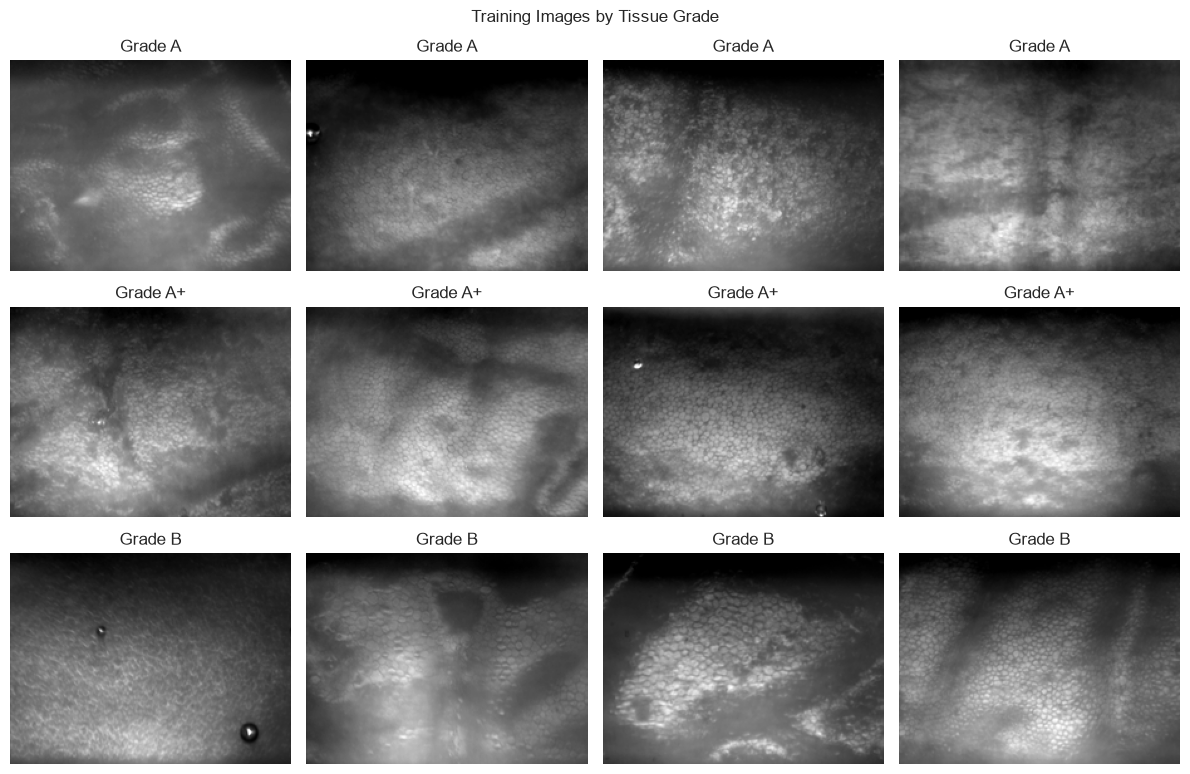

In [39]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

GRADE_ORDER = ["A", "A+", "B"]
SAMPLES_PER_GRADE = 4

fig, axes = plt.subplots(
    len(GRADE_ORDER),
    SAMPLES_PER_GRADE,
    figsize=(12, 8)
)

for row_idx, grade in enumerate(GRADE_ORDER):
    grade_df = train_df[
        train_df["Tissue_Grade_Clean"] == grade
    ].sample(
        n=min(
            SAMPLES_PER_GRADE,
            (train_df["Tissue_Grade_Clean"] == grade).sum()
        ),
        random_state=42
    )

    for col_idx, (_, row) in enumerate(grade_df.iterrows()):
        image_path = IMAGE_DIR / str(row["Selected_Image"])

        with Image.open(image_path) as img:
            img = img.convert("L")
            img.thumbnail((224, 224), Image.Resampling.LANCZOS)

            axes[row_idx, col_idx].imshow(img, cmap="gray")

        axes[row_idx, col_idx].set_title(f"Grade {grade}")
        axes[row_idx, col_idx].axis("off")

    for col_idx in range(len(grade_df), SAMPLES_PER_GRADE):
        axes[row_idx, col_idx].axis("off")

plt.suptitle("Training Images by Tissue Grade")
plt.tight_layout()
plt.show()

In [41]:
from PIL import Image
from pathlib import Path
import pandas as pd

sample_df = (
    train_df.groupby("Tissue_Grade_Clean", group_keys=False)
    .sample(n=3, random_state=42)
)

dimension_records = []

for _, row in sample_df.iterrows():
    image_path = IMAGE_DIR / str(row["Selected_Image"])

    with Image.open(image_path) as img:
        original_width, original_height = img.size

    dimension_records.append({
        "Tissue_ID": row["Tissue_ID"],
        "Grade": row["Tissue_Grade_Clean"],
        "Original_Width": original_width,
        "Original_Height": original_height,
        "Current_Model_Size": "224 x 224",
    })

print(pd.DataFrame(dimension_records))

             Tissue_ID Grade  Original_Width  Original_Height  \
0  NEB-2022-10-14317 L     A            1296              972   
1  NEB-2023-04-14964 R     A            1296              972   
2  NEB-2024-05-16077 R     A            1296              972   
3  NEB-2022-10-14324 L    A+            1296              972   
4  NEB-2023-05-15030 R    A+            1296              972   
5  NEB-2025-09-17486 L    A+            1296              972   
6  NEB-2020-10-12734 L     B            1296              972   
7  NEB-2023-09-15411 R     B            1296              972   
8  NEB-2023-06-15129 R     B            1296              972   

  Current_Model_Size  
0          224 x 224  
1          224 x 224  
2          224 x 224  
3          224 x 224  
4          224 x 224  
5          224 x 224  
6          224 x 224  
7          224 x 224  
8          224 x 224  


In [42]:
from PIL import Image
import numpy as np

IMAGE_SIZE_HIGHRES = 448

def preprocess_image_highres(image_path):
    with Image.open(image_path) as img:
        img = img.convert("L")

        # Preserve aspect ratio at higher resolution
        img.thumbnail(
            (IMAGE_SIZE_HIGHRES, IMAGE_SIZE_HIGHRES),
            Image.Resampling.LANCZOS
        )

        # Pad to a square canvas
        canvas = Image.new(
            "L",
            (IMAGE_SIZE_HIGHRES, IMAGE_SIZE_HIGHRES),
            color=0
        )

        left = (IMAGE_SIZE_HIGHRES - img.width) // 2
        top = (IMAGE_SIZE_HIGHRES - img.height) // 2
        canvas.paste(img, (left, top))

        array = np.asarray(canvas, dtype=np.float32) / 255.0

    return array[..., np.newaxis]


# Test on one existing training image
test_image_path = IMAGE_DIR / str(train_df.iloc[0]["Selected_Image"])
test_image = preprocess_image_highres(test_image_path)

print("Image shape:", test_image.shape)
print("Data type:", test_image.dtype)
print("Minimum pixel value:", test_image.min())
print("Maximum pixel value:", test_image.max())

Image shape: (448, 448, 1)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 0.69411767


In [43]:
from tqdm.auto import tqdm
import numpy as np

def load_highres_arrays(split_df):
    images = []
    labels = []

    for _, row in tqdm(
        split_df.iterrows(),
        total=len(split_df)
    ):
        image_path = IMAGE_DIR / str(row["Selected_Image"])

        images.append(preprocess_image_highres(image_path))
        labels.append(row["Tissue_Grade_Clean"])

    X = np.stack(images).astype(np.float32)
    y = np.array(labels)

    return X, y


X_train_highres, y_train_highres = load_highres_arrays(train_df)
X_val_highres, y_val_highres = load_highres_arrays(val_df)

print("Training images:", X_train_highres.shape)
print("Validation images:", X_val_highres.shape)
print("Training labels:", len(y_train_highres))
print("Validation labels:", len(y_val_highres))

  0%|          | 0/706 [00:00<?, ?it/s]

  0%|          | 0/151 [00:00<?, ?it/s]

Training images: (706, 448, 448, 1)
Validation images: (151, 448, 448, 1)
Training labels: 706
Validation labels: 151


In [44]:
X_train_highres_tensor = torch.from_numpy(
    X_train_highres
).permute(0, 3, 1, 2).contiguous()

X_val_highres_tensor = torch.from_numpy(
    X_val_highres
).permute(0, 3, 1, 2).contiguous()

y_train_highres_tensor = torch.tensor(
    [CLASS_TO_IDX[label] for label in y_train_highres],
    dtype=torch.long
)

y_val_highres_tensor = torch.tensor(
    [CLASS_TO_IDX[label] for label in y_val_highres],
    dtype=torch.long
)

print("Training tensor:", X_train_highres_tensor.shape)
print("Validation tensor:", X_val_highres_tensor.shape)
print("Training labels:", y_train_highres_tensor.shape)
print("Validation labels:", y_val_highres_tensor.shape)
print("Data type:", X_train_highres_tensor.dtype)

Training tensor: torch.Size([706, 1, 448, 448])
Validation tensor: torch.Size([151, 1, 448, 448])
Training labels: torch.Size([706])
Validation labels: torch.Size([151])
Data type: torch.float32


In [45]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE_HIGHRES = 8

train_dataset_highres = TensorDataset(
    X_train_highres_tensor,
    y_train_highres_tensor
)

val_dataset_highres = TensorDataset(
    X_val_highres_tensor,
    y_val_highres_tensor
)

train_loader_highres = DataLoader(
    train_dataset_highres,
    batch_size=BATCH_SIZE_HIGHRES,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_highres = DataLoader(
    val_dataset_highres,
    batch_size=BATCH_SIZE_HIGHRES,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, labels = next(iter(train_loader_highres))

print("Training batches:", len(train_loader_highres))
print("Validation batches:", len(val_loader_highres))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Training batches: 89
Validation batches: 19
Batch image shape: torch.Size([8, 1, 448, 448])
Batch label shape: torch.Size([8])


In [46]:
highres_cnn = CorneaCNN(num_classes=len(CLASS_NAMES)).to(device)

criterion_highres = nn.CrossEntropyLoss()

optimizer_highres = optim.Adam(
    highres_cnn.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MAX_EPOCHS_HIGHRES = 30
PATIENCE_HIGHRES = 5

best_val_f1_highres = -1.0
best_epoch_highres = 0
epochs_without_improvement_highres = 0
best_highres_state = None

print("Model: Fresh CorneaCNN")
print("Device:", next(highres_cnn.parameters()).device)
print("Trainable parameters:",
      sum(p.numel() for p in highres_cnn.parameters()
          if p.requires_grad))
print("Input size: 448 x 448")
print("Batch size:", BATCH_SIZE_HIGHRES)
print("Learning rate: 0.001")

Model: Fresh CorneaCNN
Device: cuda:0
Trainable parameters: 23715
Input size: 448 x 448
Batch size: 8
Learning rate: 0.001


In [47]:
history_highres = []

for epoch in range(MAX_EPOCHS_HIGHRES):
    highres_cnn.train()
    train_loss_sum = 0.0
    train_true = []
    train_pred = []

    for images, labels in train_loader_highres:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_highres.zero_grad(set_to_none=True)

        logits = highres_cnn(images)
        loss = criterion_highres(logits, labels)

        loss.backward()
        optimizer_highres.step()

        train_loss_sum += loss.item() * images.size(0)
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_loader_highres.dataset)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro", zero_division=0
    )

    highres_cnn.eval()
    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader_highres:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = highres_cnn(images)
            loss = criterion_highres(logits, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())

    val_loss = val_loss_sum / len(val_loader_highres.dataset)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro", zero_division=0
    )

    history_highres.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_macro_f1": val_f1,
    })

    print(
        f"Epoch {epoch + 1:02d}/{MAX_EPOCHS_HIGHRES} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train macro F1: {train_f1:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1_highres:
        best_val_f1_highres = val_f1
        best_epoch_highres = epoch + 1
        best_highres_state = copy.deepcopy(highres_cnn.state_dict())
        epochs_without_improvement_highres = 0
    else:
        epochs_without_improvement_highres += 1

    if epochs_without_improvement_highres >= PATIENCE_HIGHRES:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break

if best_highres_state is None:
    raise RuntimeError("High-resolution CNN training produced no checkpoint.")

highres_cnn.load_state_dict(best_highres_state)
history_highres_df = pd.DataFrame(history_highres)

print(f"\nBest epoch: {best_epoch_highres}")
print(f"Best validation macro F1: {best_val_f1_highres:.4f}")

Epoch 01/30 | Train loss: 1.0193 | Train macro F1: 0.2996 | Val loss: 1.0013 | Val macro F1: 0.2290
Epoch 02/30 | Train loss: 1.0035 | Train macro F1: 0.2435 | Val loss: 1.0041 | Val macro F1: 0.2290
Epoch 03/30 | Train loss: 1.0028 | Train macro F1: 0.2360 | Val loss: 0.9923 | Val macro F1: 0.2290
Epoch 04/30 | Train loss: 0.9988 | Train macro F1: 0.2327 | Val loss: 1.0215 | Val macro F1: 0.2659
Epoch 05/30 | Train loss: 0.9971 | Train macro F1: 0.2477 | Val loss: 1.0080 | Val macro F1: 0.2446
Epoch 06/30 | Train loss: 1.0145 | Train macro F1: 0.2377 | Val loss: 0.9996 | Val macro F1: 0.2290
Epoch 07/30 | Train loss: 1.0064 | Train macro F1: 0.2546 | Val loss: 1.0272 | Val macro F1: 0.2290
Epoch 08/30 | Train loss: 1.0003 | Train macro F1: 0.2531 | Val loss: 1.0079 | Val macro F1: 0.2789
Epoch 09/30 | Train loss: 0.9966 | Train macro F1: 0.2737 | Val loss: 1.0225 | Val macro F1: 0.2290
Epoch 10/30 | Train loss: 0.9827 | Train macro F1: 0.2410 | Val loss: 0.9680 | Val macro F1: 0.2290
